# 01 — Dataset exploration (EDA)

Exploration of the raw PathSnap data. Partitions used: **train** (80 trips) and **student_test** (10 trips).
Evaluator-test data is not used anywhere.

All numbers below are computed live by the project code in `pathsnap/` (the same code as the command-line scripts).

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathsnap.config import DATA_ROOT, PARTITIONS, MAX_SPEED_MS
from pathsnap.data_processing.loader import list_trips, load_trip, trip_dir
from pathsnap.data_processing.inventory import trip_stats

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
plt.rcParams["figure.dpi"] = 110
print("data root:", DATA_ROOT)

data root: /run/media/amogh-herle/DATA/PESU/ML_LAB/HACKATHON/Student folder


## 1. File availability per partition

In [2]:
rows = []
for p in PARTITIONS:
    for t in list_trips(p):
        d = trip_dir(t, p)
        rows.append({"partition": p, "trip_id": t,
                     **{ext: (d / f"{t}.{ext}").exists() for ext in ["track", "nodes", "arcs", "route"]},
                     "size_mb": sum(f.stat().st_size for f in d.iterdir()) / 1e6})
files = pd.DataFrame(rows)
files.groupby("partition").agg(trips=("trip_id", "size"), track=("track", "sum"), nodes=("nodes", "sum"),
                               arcs=("arcs", "sum"), route=("route", "sum"), total_mb=("size_mb", "sum")).round(1)

,trips,track,nodes,arcs,route,total_mb
partition,,,,,,
student_test,10,10,10,10,10,4.4
train,80,80,80,80,80,89.7


## 2. Raw file structure (train trip 00000001)

No headers; whitespace-separated. Column names below are assigned by the loader.

In [3]:
d = trip_dir("00000001", "train")
for ext, names in [("track", ["lon", "lat", "t"]), ("nodes", ["lon", "lat"]),
                   ("arcs", ["from_node", "to_node"]), ("route", ["arc_id"])]:
    raw = pd.read_csv(d / f"00000001.{ext}", sep=r"\s+", header=None, names=names)
    print(f"--- .{ext}: {len(raw):,} rows, dtypes {dict(raw.dtypes.astype(str))}")
    display(raw.head(3))

--- .track: 1,315 rows, dtypes {'lon': 'float64', 'lat': 'float64', 't': 'float64'}


,lon,lat,t
0,8.595203,49.844053,1.0
1,8.595294,49.844441,2.0
2,8.595352,49.844883,3.0


--- .nodes: 88,809 rows, dtypes {'lon': 'float64', 'lat': 'float64'}


,lon,lat
0,8.581679,49.857880
1,8.584637,49.858295
2,8.580173,49.858567


--- .arcs: 165,790 rows, dtypes {'from_node': 'int64', 'to_node': 'int64'}


,from_node,to_node
0,0,281
1,0,1
2,0,5


--- .route: 525 rows, dtypes {'arc_id': 'int64'}


,arc_id
0,2641
1,64973
2,133948


## 3. Per-trip inventory (both partitions)

Loads every trip, projects it to its own UTM zone and computes timing, speed, network and route statistics.

In [4]:
inv_rows, steps = [], []
for p in PARTITIONS:
    for t in list_trips(p):
        trip = load_trip(t, p)
        inv_rows.append(trip_stats(trip))
        tr = trip.track
        dt = np.diff(tr["t"].to_numpy())
        step = np.hypot(np.diff(tr["x"].to_numpy()), np.diff(tr["y"].to_numpy()))
        steps.append(pd.DataFrame({"partition": p, "trip_id": t, "dt": dt,
                                   "speed": np.where(dt > 0, step / np.where(dt > 0, dt, 1), np.nan)}))
inv = pd.DataFrame(inv_rows)
steps = pd.concat(steps, ignore_index=True)
cols = ["n_points", "duration_s", "frac_dt_1s", "max_dt", "n_gaps_gt_10s", "n_nodes", "n_arcs",
        "n_weak_components", "largest_wcc_frac", "n_route_arcs", "route_continuity"]
inv.groupby("partition")[cols].describe().T.loc[(slice(None), ["min", "50%", "mean", "max"]), :].round(3)

,partition,student_test,train
n_points,min,262.000,361.000
duration_s,min,265.000,451.000
frac_dt_1s,min,0.861,0.531
max_dt,min,1.000,1.000
n_gaps_gt_10s,min,0.000,0.000
n_nodes,min,1770.000,299.000
n_arcs,min,3577.000,649.000
n_weak_components,min,5.000,1.000
largest_wcc_frac,min,0.874,0.693
n_route_arcs,min,95.000,59.000


## 4. Missing and invalid values

In [5]:
checks = ["n_nan", "n_non_increasing_t", "n_arcs_bad_node_ref", "n_route_bad_arc_ref",
          "n_self_loops", "n_isolated_nodes", "n_speed_gt_max"]
q = inv.groupby("partition")[checks].sum()
q["tracks_outside_network_bbox"] = (~inv["track_inside_net_bbox"]).groupby(inv["partition"]).sum()
q

,n_nan,n_non_increasing_t,n_arcs_bad_node_ref,n_route_bad_arc_ref,n_self_loops,n_isolated_nodes,n_speed_gt_max,tracks_outside_network_bbox
partition,,,,,,,,
student_test,0,0,0,0,2,0,0,0
train,0,0,0,0,22,0,62,0


No missing values, no non-increasing timestamps and no broken id references in either partition. The data problems are semantic (below).

## 5. GPS observations per trip

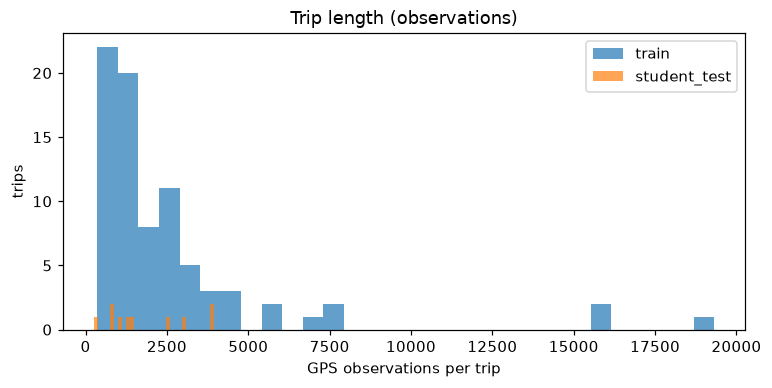

,sum,min,median,max
partition,,,,
student_test,19160,262,1420.0,3958
train,208417,361,1529.0,19313


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.5))
for p, c in zip(PARTITIONS, ["#1f77b4", "#ff7f0e"]):
    ax.hist(inv.loc[inv.partition == p, "n_points"], bins=30, alpha=0.7, label=p, color=c)
ax.set_xlabel("GPS observations per trip"); ax.set_ylabel("trips"); ax.legend()
ax.set_title("Trip length (observations)"); plt.show()
inv.groupby("partition")["n_points"].agg(["sum", "min", "median", "max"])

## 6. Timestamp ordering and sampling intervals

In [7]:
bins = pd.cut(steps["dt"], [0, 1.5, 2.5, 10, 30, 600, np.inf],
              labels=["1 s", "2 s", "3-10 s", "10-30 s", "30 s-10 min", "> 10 min"])
pd.crosstab(steps["partition"], bins, normalize="index").mul(100).round(3)

dt,1 s,2 s,3-10 s,10-30 s,30 s-10 min,> 10 min
partition,,,,,,
student_test,98.621,0.658,0.580,0.131,0.01,0.000
train,96.509,2.081,1.127,0.219,0.06,0.004


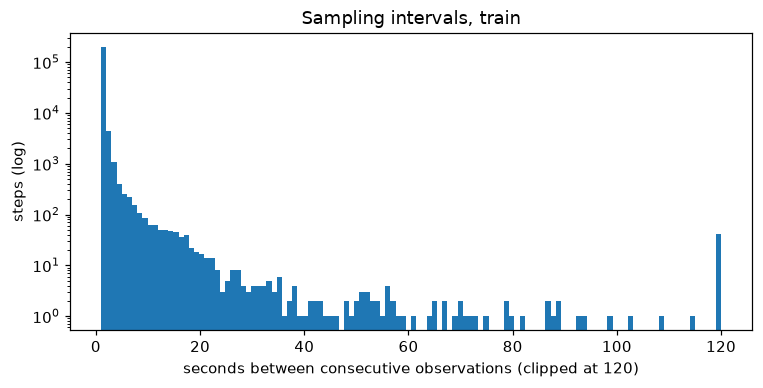

,partition,trip_id,n_points,duration_s,max_dt,n_gaps_gt_10s,frac_dt_1s
72,train,00000090,536,154030.0,153064.0,6,0.581308
61,train,00000078,2909,57836.0,52810.0,25,0.755158
55,train,00000069,2067,5558.0,2658.0,2,0.989351
16,train,00000021,15783,18605.0,2161.0,2,0.999620
8,train,00000011,2828,3735.0,909.0,1,0.999646
34,train,00000042,7739,12377.0,670.0,37,0.989532
64,train,00000081,3224,8481.0,536.0,86,0.719826
18,train,00000024,801,1541.0,458.0,2,0.971250


In [8]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(steps.loc[steps.partition == "train", "dt"].clip(upper=120), bins=120, color="#1f77b4", log=True)
ax.set_xlabel("seconds between consecutive observations (clipped at 120)")
ax.set_ylabel("steps (log)"); ax.set_title("Sampling intervals, train"); plt.show()
inv.sort_values("max_dt", ascending=False)[["partition", "trip_id", "n_points", "duration_s", "max_dt",
                                            "n_gaps_gt_10s", "frac_dt_1s"]].head(8)

Nominal 1 Hz holds for most steps, but some trips contain gaps of many hours (train 00000090: one gap of ~42 h).

## 7. Implied speed between consecutive observations

percentiles 50/90/99/99.9/99.99/max (m/s): [ 11.1  27.4  46.4  67.1  97.2 180.5]
 threshold_m_s  steps_above
            50         1530
            70          150
            90           34
           120            6
           200            0


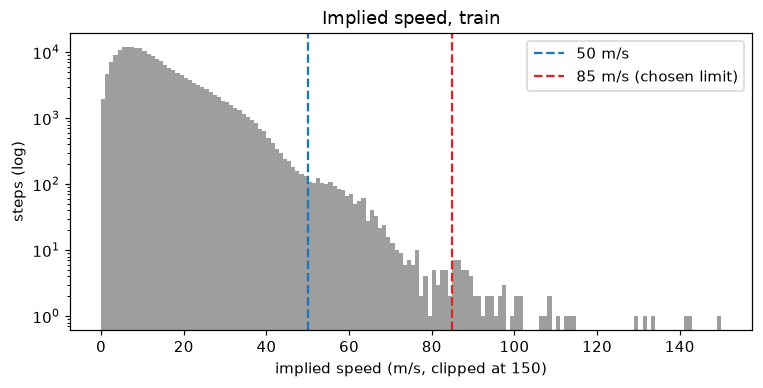

In [9]:
s = steps.loc[steps.partition == "train", "speed"].dropna()
print("percentiles 50/90/99/99.9/99.99/max (m/s):", np.percentile(s, [50, 90, 99, 99.9, 99.99, 100]).round(1))
print(pd.DataFrame({"threshold_m_s": [50, 70, 90, 120, 200],
                    "steps_above": [(s > v).sum() for v in [50, 70, 90, 120, 200]]}).to_string(index=False))
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(s.clip(upper=150), bins=150, color="#9e9e9e", log=True)
for v, lab in [(50, "50 m/s"), (MAX_SPEED_MS, f"{MAX_SPEED_MS:.0f} m/s (chosen limit)")]:
    ax.axvline(v, color="#d62728" if v == MAX_SPEED_MS else "#1f77b4", ls="--", label=lab)
ax.set_xlabel("implied speed (m/s, clipped at 150)"); ax.set_ylabel("steps (log)")
ax.set_title("Implied speed, train"); ax.legend(); plt.show()

In [10]:
t1 = steps[(steps.trip_id == "00000001")]["speed"]
print("train 00000001 speed median/p99/max:", np.nanpercentile(t1, [50, 99, 100]).round(1),
      "| share above 50 m/s:", round((t1 > 50).mean(), 3))

train 00000001 speed median/p99/max: [41.4 64.  72.4] | share above 50 m/s: 0.259


Trip 00000001 is an autobahn drive at a median 41 m/s: real speeds above 50 m/s are common, so a 50 m/s outlier limit would be wrong.

## 8. Geographical extent

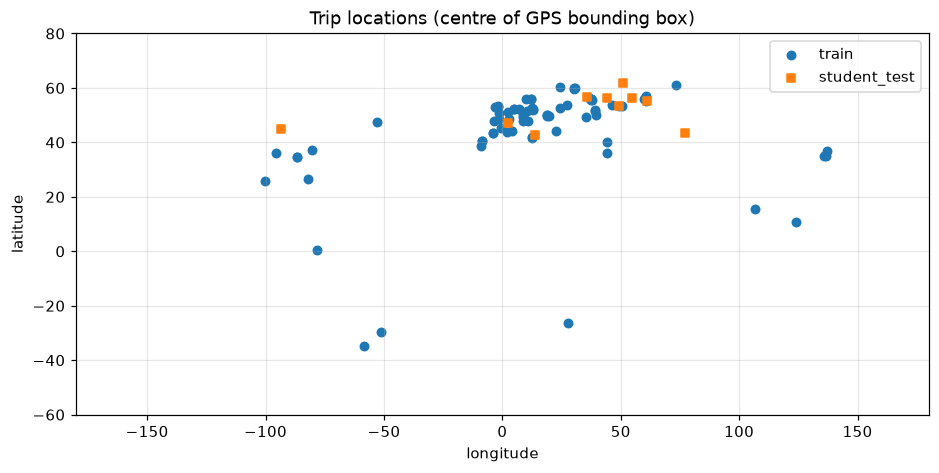

distinct UTM zones: {'student_test': 9, 'train': 25}


,count,mean,std,min,25%,50%,75%,max
partition,,,,,,,,
student_test,10.0,14.2,14.3,4.3,5.9,7.2,15.4,48.2
train,80.0,19.8,20.5,1.4,5.4,9.5,28.5,78.4


In [11]:
inv["c_lon"] = (inv.lon_min + inv.lon_max) / 2
inv["c_lat"] = (inv.lat_min + inv.lat_max) / 2
fig, ax = plt.subplots(figsize=(10, 4.5))
for p, c, m in zip(PARTITIONS, ["#1f77b4", "#ff7f0e"], ["o", "s"]):
    sub = inv[inv.partition == p]
    ax.scatter(sub.c_lon, sub.c_lat, c=c, marker=m, label=p, s=30)
ax.set_xlim(-180, 180); ax.set_ylim(-60, 80); ax.grid(alpha=0.3)
ax.set_xlabel("longitude"); ax.set_ylabel("latitude"); ax.legend()
ax.set_title("Trip locations (centre of GPS bounding box)"); plt.show()
print("distinct UTM zones:", inv.groupby("partition")["crs"].nunique().to_dict())
inv["extent_km"] = np.hypot((inv.lon_max - inv.lon_min) * 111 * np.cos(np.radians(inv.c_lat)),
                            (inv.lat_max - inv.lat_min) * 111)
inv.groupby("partition")["extent_km"].describe().round(1)

Trips are spread over several continents, so a single fixed projection cannot work; each trip is projected to the UTM zone of its own median GPS position.

## 9. Road network size and connectivity

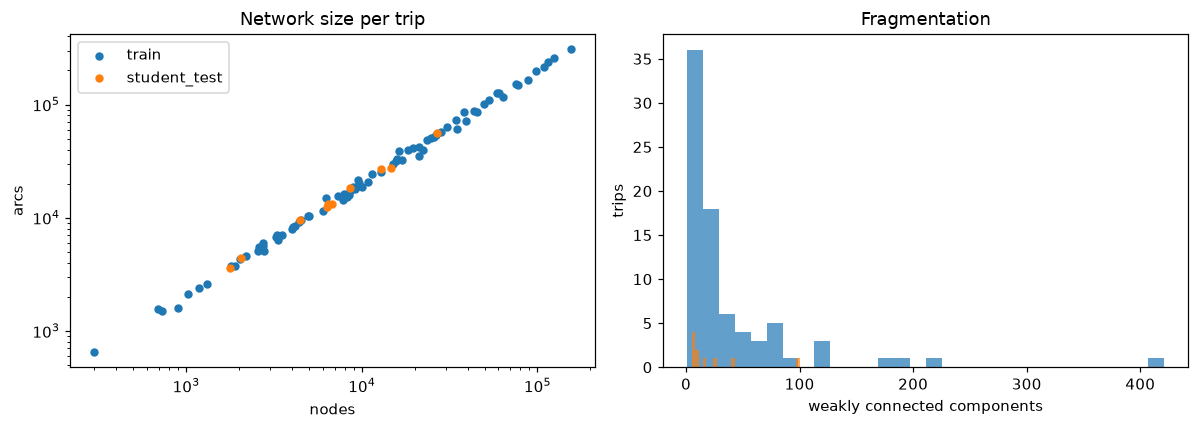

,n_nodes,n_arcs,median_arc_len_m,n_weak_components,n_strong_components,largest_wcc_frac
partition,,,,,,
student_test,6596.5,13145.0,31.946,11.0,53.5,0.971
train,9608.0,19526.5,24.578,20.0,127.0,0.981


In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for p, c in zip(PARTITIONS, ["#1f77b4", "#ff7f0e"]):
    sub = inv[inv.partition == p]
    axes[0].scatter(sub.n_nodes, sub.n_arcs, c=c, label=p, s=20)
    axes[1].hist(sub.n_weak_components, bins=30, alpha=0.7, color=c, label=p)
axes[0].set_xscale("log"); axes[0].set_yscale("log")
axes[0].set_xlabel("nodes"); axes[0].set_ylabel("arcs"); axes[0].set_title("Network size per trip"); axes[0].legend()
axes[1].set_xlabel("weakly connected components"); axes[1].set_ylabel("trips"); axes[1].set_title("Fragmentation")
plt.tight_layout(); plt.show()
inv.groupby("partition")[["n_nodes", "n_arcs", "median_arc_len_m", "n_weak_components",
                          "n_strong_components", "largest_wcc_frac"]].median().round(3)

Arcs ≈ 2 × nodes: most streets are stored in both directions (u→v and v→u). Networks are fragmented into many components, which matters for shortest-path transitions in the HMM.

## 10. Reference routes

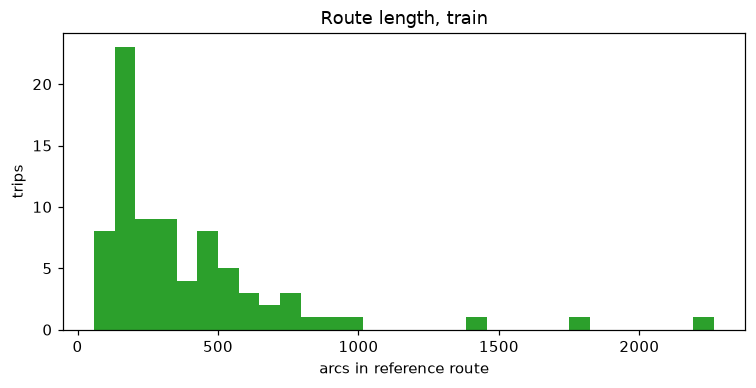

,partition,trip_id,n_route_arcs,n_route_breaks,route_continuity,route_revisits
1,train,00000002,262,1,0.996169,0
6,train,00000008,173,0,1.000000,1
13,train,00000018,166,0,1.000000,9
14,train,00000019,545,3,0.994485,0
26,train,00000033,169,1,0.994048,0
33,train,00000041,340,1,0.997050,0
34,train,00000042,1440,1,0.999305,0
55,train,00000069,467,1,0.997854,29
60,train,00000075,108,2,0.981308,2
63,train,00000080,139,1,0.992754,0


In [13]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(inv.loc[inv.partition == "train", "n_route_arcs"], bins=30, color="#2ca02c")
ax.set_xlabel("arcs in reference route"); ax.set_ylabel("trips"); ax.set_title("Route length, train"); plt.show()
inv["route_revisits"] = inv.n_route_arcs - inv.n_route_unique_arcs
inv.loc[(inv.route_continuity < 1) | (inv.route_revisits > 0),
        ["partition", "trip_id", "n_route_arcs", "n_route_breaks", "route_continuity", "route_revisits"]]

Some reference routes contain breaks (consecutive arcs that are not connected) and some revisit arcs. The route is reference information, not verified ground truth.

## 11. Interactive map (student_test trip 00000000)

GPS observations, nearby road network, reference route, start/end markers. Generated by `pathsnap/viz/maps.py`.

In [ ]:
from pathsnap.viz.maps import trip_map
trip_map(load_trip("00000000", "student_test"), title="student_test / 00000000")

## 12. Summary of data-quality issues

| Issue | Partition | Decision |
|---|---|---|
| Trips on several continents | both | per-trip UTM projection |
| Real autobahn speeds up to ~72 m/s | train | outlier limit 85 m/s, not 50 m/s |
| Gaps up to ~42 h | train | split track into segments at gaps > 30 s |
| Route breaks and revisited arcs | both | monotonic label alignment; HMM must tolerate breaks |
| Fragmented networks | both | HMM transitions need a fallback when no path exists |

See `02_preprocessing.ipynb` for how each decision is implemented and checked.